In [1]:
!pip install nltk seaborn


In [2]:
!pip install -q nltk seaborn

import re, string
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

for pkg in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(pkg)

SEED = 42

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

print(len(stopwords.words("english")))
print(word_tokenize("Free entry in 2 a wkly comp!"))

198
['Free', 'entry', 'in', '2', 'a', 'wkly', 'comp', '!']


In [4]:
import nltk
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [5]:
df = pd.read_csv("SMSSpamCollection", encoding="utf-8", sep='\t', header=None, names=["label", "text"])

In [6]:
print(df.shape)
print(df.isna().sum())
print("Duplicate messages:", df.duplicated().sum())
df.head()

(5572, 2)
label    0
text     0
dtype: int64
Duplicate messages: 403


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [7]:
df = df.drop_duplicates().reset_index(drop=True)
df["y"] = (df["label"] == "spam").astype(int)
print(df.shape)


(5169, 3)


In [8]:
print(df.columns.tolist())

['label', 'text', 'y']


In [9]:
df = df[["label", "text"]].copy()
df["y"] = (df["label"] == "spam").astype(int)
print(df.shape)
print(df.columns.tolist())

(5169, 3)
['label', 'text', 'y']


In [10]:
print(df.groupby("label")["y"].mean())

label
ham     0.0
spam    1.0
Name: y, dtype: float64


label
ham     4516
spam     653
Name: count, dtype: int64 

label
ham     87.37
spam    12.63
Name: count, dtype: float64


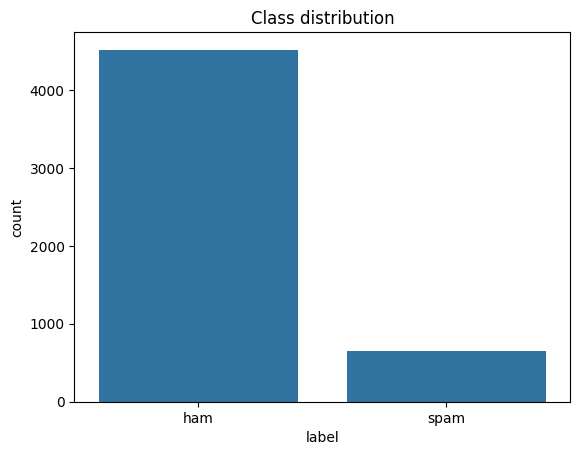

In [11]:
counts = df["label"].value_counts()
print(counts, "\n")
print((counts / len(df) * 100).round(2))

sns.countplot(data=df, x="label", order=["ham", "spam"])
plt.title("Class distribution")
plt.show()

In [12]:
df["char_count"]   = df.text.str.len()
df["word_count"]   = df.text.str.split().str.len()
df["digit_count"]  = df.text.str.count(r"\d")
df["upper_ratio"]  = df.text.apply(lambda msg: sum(ch.isupper() for ch in msg) / max(len(msg), 1))
df["punct_count"]  = df.text.apply(lambda msg: sum(ch in string.punctuation for ch in msg))
df["contains_url"]      = df.text.str.contains(r"(?:https?://|www\.)", case=False, regex=True)
df["contains_currency"] = df.text.str.contains(r"[£$€]", regex=True)
df["contains_phone_like"] = df.text.str.contains(r"\b\d{5,}\b", regex=True)
df["contains_shouting"] = df.text.str.contains(r"\b[A-Z]{3,}\b", regex=True)

feature_cols = ["char_count", "word_count", "digit_count", "upper_ratio", "punct_count",
                "contains_url", "contains_currency", "contains_phone_like", "contains_shouting"]

print(df.groupby("label")[feature_cols].mean().round(3).T)

label                   ham     spam
char_count           70.906  137.704
word_count           14.240   23.740
digit_count           0.297   15.489
upper_ratio           0.057    0.110
punct_count           3.830    5.643
contains_url          0.000    0.138
contains_currency     0.004    0.332
contains_phone_like   0.001    0.737
contains_shouting     0.064    0.695


In [13]:
print(df.groupby("label")["contains_url"].sum())


label
ham      1
spam    90
Name: contains_url, dtype: int64


In [14]:
STOP_RAW = set(stopwords.words("english"))

def frequent_words(cls, top_n=20):
    words = " ".join(df.loc[df.label == cls, "text"]).lower().split()
    words = [w.strip(string.punctuation) for w in words]
    words = [w for w in words if w and w not in STOP_RAW]
    return Counter(words).most_common(top_n)

print("SPAM:", frequent_words("spam"))
print()
print("HAM: ", frequent_words("ham"))

SPAM: [('call', 302), ('free', 188), ('2', 155), ('txt', 126), ('u', 123), ('ur', 119), ('mobile', 105), ('stop', 105), ('text', 103), ('4', 97), ('claim', 96), ('reply', 93), ('prize', 81), ('get', 69), ('new', 64), ('send', 58), ('urgent', 58), ('nokia', 54), ('cash', 51), ('contact', 51)]

HAM:  [('u', 891), ('get', 295), ('2', 292), ('lt;#&gt', 254), ('ok', 247), ('go', 242), ('got', 226), ('like', 221), ('know', 221), ('come', 211), ('good', 207), ('ur', 202), ('call', 186), ('time', 181), ('love', 173), ('ü', 169), ('day', 169), ('4', 166), ('going', 162), ('want', 160)]


In [15]:
text = "Call me at &lt;#&gt; pm"
text = text.replace("&lt;", "<").replace("&gt;", ">")
text = re.sub(r"<#>", " numtoken ", text)
print(text)

Call me at  numtoken  pm


In [16]:
STOP_WORDS = set(stopwords.words("english"))
STOP_WORDS -= {"no", "not", "nor"}
STOP_WORDS |= {"u", "ur"}           # SMS abbreviations of you / your
stemmer = PorterStemmer()
TOKENS_KEEP = {"urltoken", "emailtoken", "moneytoken", "phonetoken", "numtoken"}

def clean_message(msg, drop_stopwords=True, apply_stem=True):
    msg = msg.replace("&lt;", "<").replace("&gt;", ">").replace("&amp;", "&")
    msg = msg.replace("å£", "£").replace("Â£", "£")
    msg = msg.lower()
    msg = re.sub(r"<#>", " numtoken ", msg)
    msg = re.sub(r"(?:https?://\S+|www\.\S+)", " urltoken ", msg)
    msg = re.sub(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b", " emailtoken ", msg)
    msg = re.sub(r"[£$€]\s?\d+(?:[.,]\d+)*", " moneytoken ", msg)
    msg = re.sub(r"\b\d{5,}\b", " phonetoken ", msg)
    msg = re.sub(r"\b\d+(?:[.,]\d+)*\b", " numtoken ", msg)
    msg = re.sub(r"[^a-z\s]", " ", msg)
    words = word_tokenize(msg)
    if drop_stopwords:
        words = [w for w in words if w not in STOP_WORDS]
    if apply_stem:
        words = [w if w in TOKENS_KEEP else stemmer.stem(w) for w in words]
    return words

df["tokens"] = df["text"].apply(clean_message)
df["clean_text"] = df["tokens"].apply(" ".join)

def fix_empty_message(msg):
    words = clean_message(
        msg,
        drop_stopwords=False,
        apply_stem=False
    )

    if len(words) == 0:
        words = ["emptytoken"]

    return words

empty_mask = df["clean_text"].str.len() == 0

df.loc[empty_mask, "tokens"] = df.loc[
    empty_mask, "text"
].apply(fix_empty_message)

df["clean_text"] = df["tokens"].apply(" ".join)

print("Empty messages:",
      (df["clean_text"].str.len() == 0).sum())

Empty messages: 0


In [17]:
pd.set_option("display.max_colwidth", 120)
sample = pd.concat([df[df.label == "spam"].sample(3, random_state=SEED),
                    df[df.label == "ham"].sample(3, random_state=SEED)])
sample[["label", "text", "clean_text"]]

,label,text,clean_text
749,spam,"Romantic Paris. 2 nights, 2 flights from £79 Book now 4 next year. Call 08704439680Ts&Cs apply.",romant pari numtoken night numtoken flight moneytoken book numtoken next year call ts cs appli
1988,spam,"URGENT! Your mobile No *********** WON a £2,000 Bonus Caller Prize on 02/06/03! This is the 2nd attempt to reach YOU...",urgent mobil no moneytoken bonu caller prize numtoken numtoken numtoken nd attempt reach call phonetoken asap box n ...
1400,spam,Free 1st week entry 2 TEXTPOD 4 a chance 2 win 40GB iPod or £250 cash every wk. Txt POD to 84128 Ts&Cs www.textpod.n...,free st week entri numtoken textpod numtoken chanc numtoken win gb ipod moneytoken cash everi wk txt pod phonetoken ...
1819,ham,"Sorry, I can't help you on this.",sorri help
1654,ham,"How's my loverboy doing ? What does he do that keeps him from coming to his Queen, hmmm ? Doesn't he ache to speak t...",loverboy keep come queen hmmm ach speak miss despar
4586,ham,Sitting in mu waiting for everyone to get out of my suite so I can take a shower,sit mu wait everyon get suit take shower


In [18]:
msg = df[df.label == "spam"].iloc[0].text
print("RAW        :", msg)
print("LOWER      :", msg.lower())
print("+REGEX     :", " ".join(clean_message(msg, drop_stopwords=False, apply_stem=False)))
print("+STOPWORDS :", " ".join(clean_message(msg, drop_stopwords=True, apply_stem=False)))
print("+STEMMING  :", " ".join(clean_message(msg)))

RAW        : Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
LOWER      : free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005. text fa to 87121 to receive entry question(std txt rate)t&c's apply 08452810075over18's
+REGEX     : free entry in numtoken a wkly comp to win fa cup final tkts st may numtoken text fa to phonetoken to receive entry question std txt rate t c s apply over s
+STOPWORDS : free entry numtoken wkly comp win fa cup final tkts st may numtoken text fa phonetoken receive entry question std txt rate c apply
+STEMMING  : free entri numtoken wkli comp win fa cup final tkt st may numtoken text fa phonetoken receiv entri question std txt rate c appli


In [19]:
vocab_raw   = set(w for t in df.text for w in t.lower().split())
vocab_clean = set(w for toks in df.tokens for w in toks)
print(f"Vocabulary: {len(vocab_raw)} -> {len(vocab_clean)}")
print("Empty messages after cleaning:", (df.clean_text.str.len() == 0).sum())

Vocabulary: 13579 -> 6273
Empty messages after cleaning: 0


In [20]:
vocab_raw   = set(w for t in df.text for w in t.lower().split())
vocab_clean = set(w for toks in df.tokens for w in toks)
print(f"Vocabulary: {len(vocab_raw)} -> {len(vocab_clean)}")
print("Empty messages after cleaning:", (df.clean_text.str.len() == 0).sum())


Vocabulary: 13579 -> 6273
Empty messages after cleaning: 0


In [21]:
for cls in ["spam", "ham"]:
    allw = [w for toks in df.loc[df.label == cls, "tokens"] for w in toks]
    print(cls.upper(), Counter(allw).most_common(15), "\n")

SPAM [('numtoken', 891), ('phonetoken', 596), ('call', 346), ('moneytoken', 268), ('free', 197), ('p', 158), ('txt', 148), ('text', 128), ('mobil', 121), ('stop', 116), ('repli', 104), ('claim', 98), ('urltoken', 90), ('prize', 84), ('min', 78)] 

HAM [('numtoken', 1061), ('go', 412), ('not', 398), ('get', 358), ('come', 280), ('no', 276), ('ok', 256), ('call', 242), ('got', 240), ('like', 238), ('know', 237), ('love', 231), ('time', 226), ('day', 220), ('good', 218)] 



In [22]:
print(df.loc[df.clean_text.str.len() == 0, ["label", "text"]])
pd.set_option("display.max_colwidth", 120)
sample = pd.concat([df[df.label == "spam"].sample(3, random_state=SEED),
                    df[df.label == "ham"].sample(3, random_state=SEED)])
sample[["label", "text", "clean_text"]]

Empty DataFrame
Columns: [label, text]
Index: []


,label,text,clean_text
749,spam,"Romantic Paris. 2 nights, 2 flights from £79 Book now 4 next year. Call 08704439680Ts&Cs apply.",romant pari numtoken night numtoken flight moneytoken book numtoken next year call ts cs appli
1988,spam,"URGENT! Your mobile No *********** WON a £2,000 Bonus Caller Prize on 02/06/03! This is the 2nd attempt to reach YOU...",urgent mobil no moneytoken bonu caller prize numtoken numtoken numtoken nd attempt reach call phonetoken asap box n ...
1400,spam,Free 1st week entry 2 TEXTPOD 4 a chance 2 win 40GB iPod or £250 cash every wk. Txt POD to 84128 Ts&Cs www.textpod.n...,free st week entri numtoken textpod numtoken chanc numtoken win gb ipod moneytoken cash everi wk txt pod phonetoken ...
1819,ham,"Sorry, I can't help you on this.",sorri help
1654,ham,"How's my loverboy doing ? What does he do that keeps him from coming to his Queen, hmmm ? Doesn't he ache to speak t...",loverboy keep come queen hmmm ach speak miss despar
4586,ham,Sitting in mu waiting for everyone to get out of my suite so I can take a shower,sit mu wait everyon get suit take shower


In [23]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    df.index, test_size=0.2, stratify=df["y"], random_state=SEED)

train_df = df.loc[train_idx]
test_df  = df.loc[test_idx]

train_df.to_csv("train.csv", index=False)
test_df.to_csv("test.csv", index=False)

print("Train:", train_df.shape, " Test:", test_df.shape)
print("Spam ratio  train:", round(train_df["y"].mean(), 4),
      " test:", round(test_df["y"].mean(), 4))

Train: (4135, 14)  Test: (1034, 14)
Spam ratio  train: 0.1262  test: 0.1267


In [24]:
print(len(set(train_df.index) & set(test_df.index)))

0


In [25]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")